# EDA do Dataset: Bitcoin Alpha Trust Weight Signed Network

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

ModuleNotFoundError: No module named 'seaborn'

## Carregando o Dataset

In [25]:
# URL do dataset compactado no site do SNAP
url = "https://snap.stanford.edu/data/soc-sign-bitcoinalpha.csv.gz"

# Carregando o dataset diretamente do link de download
# As colunas originais são: SOURCE, TARGET, RATING, TIME
columns = ["SOURCE", "TARGET", "RATING", "TIME"]
df = pd.read_csv(url, compression="gzip", names=columns)
df.head()

,SOURCE,TARGET,RATING,TIME
0,7188,1,10,1407470400
1,430,1,10,1376539200
2,3134,1,10,1369713600
3,3026,1,10,1350014400
4,3010,1,10,1347854400


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

### Dimensão e Tipos de Dados

In [26]:
df.shape

(24186, 4)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24186 entries, 0 to 24185
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   SOURCE  24186 non-null  int64
 1   TARGET  24186 non-null  int64
 2   RATING  24186 non-null  int64
 3   TIME    24186 non-null  int64
dtypes: int64(4)
memory usage: 755.9 KB


In [28]:
df.describe()

,SOURCE,TARGET,RATING,TIME
count,24186.000000,24186.000000,24186.000000,2.418600e+04
mean,864.029314,1051.093815,1.463946,1.347099e+09
std,1592.085638,1871.765504,2.903656,3.397039e+07
min,1.000000,1.000000,-10.000000,1.289192e+09
25%,58.000000,66.000000,1.000000,1.312690e+09
50%,238.000000,279.000000,1.000000,1.345435e+09
75%,898.000000,1068.000000,2.000000,1.369454e+09
max,7604.000000,7604.000000,10.000000,1.453439e+09


### Duplicadas

In [29]:
df.duplicated().sum()

np.int64(0)

## 2. Dados Faltantes

In [30]:
df.isna().sum()

,0
SOURCE,0
TARGET,0
RATING,0
TIME,0


## 3. Princípio Distribucional

Vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [31]:
VARS_QUANT = ["RATING", "TIME"]
VARS_QUALI = ["SOURCE", "TARGET"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
RATING,1.46,1.00,2.90,-10.00,10.00,-1.35,7.64
TIME,1347098654.83,1345435200.00,33970387.65,1289192400.00,1453438800.00,0.44,-0.58


Olhando para os resultados gerados na tabela de estatísticas descritivas:

*   `RATING`:
    * **É altamente assimétrica e possui cauda pesada.**
    * A sua assimetria (*skewness*) é de **-1.35** (em módulo é maior que 1, com sinal negativo indicando assimetria à esquerda/negativa).
    * A sua curtose (*kurtosis*) é de **7.64** (bem maior que 2, indicando uma distribuição muito afunilada/leptocúrtica com caudas pesadas devido a notas extremas como -10 e +10).

* `TIME`:
    * **Não é assimétrica e nem possui cauda pesada.**
    * Sua assimetria (*skewness*) é de apenas **0.44** (abaixo de 1).
    * Sua curtose (*kurtosis*) é de **-0.58** (menor que 2 em módulo, indicando uma distribuição relativamente achatada e sem caudas extremas fora do normal).


### Distribuições de dados

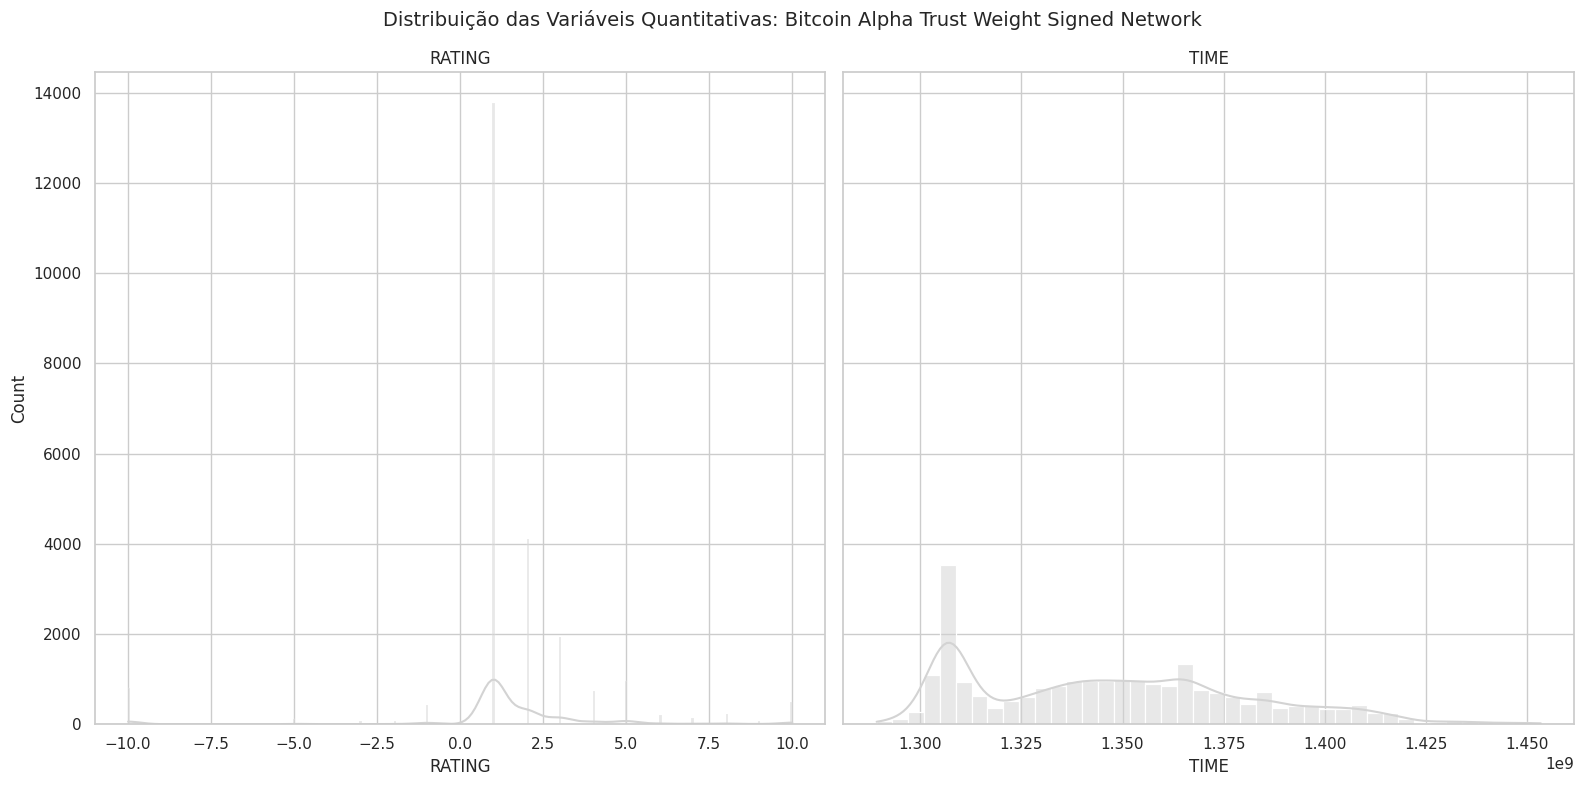

In [32]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Distribuição das Variáveis Quantitativas: Bitcoin Alpha Trust Weight Signed Network", fontsize=14)
plt.tight_layout()
plt.show()

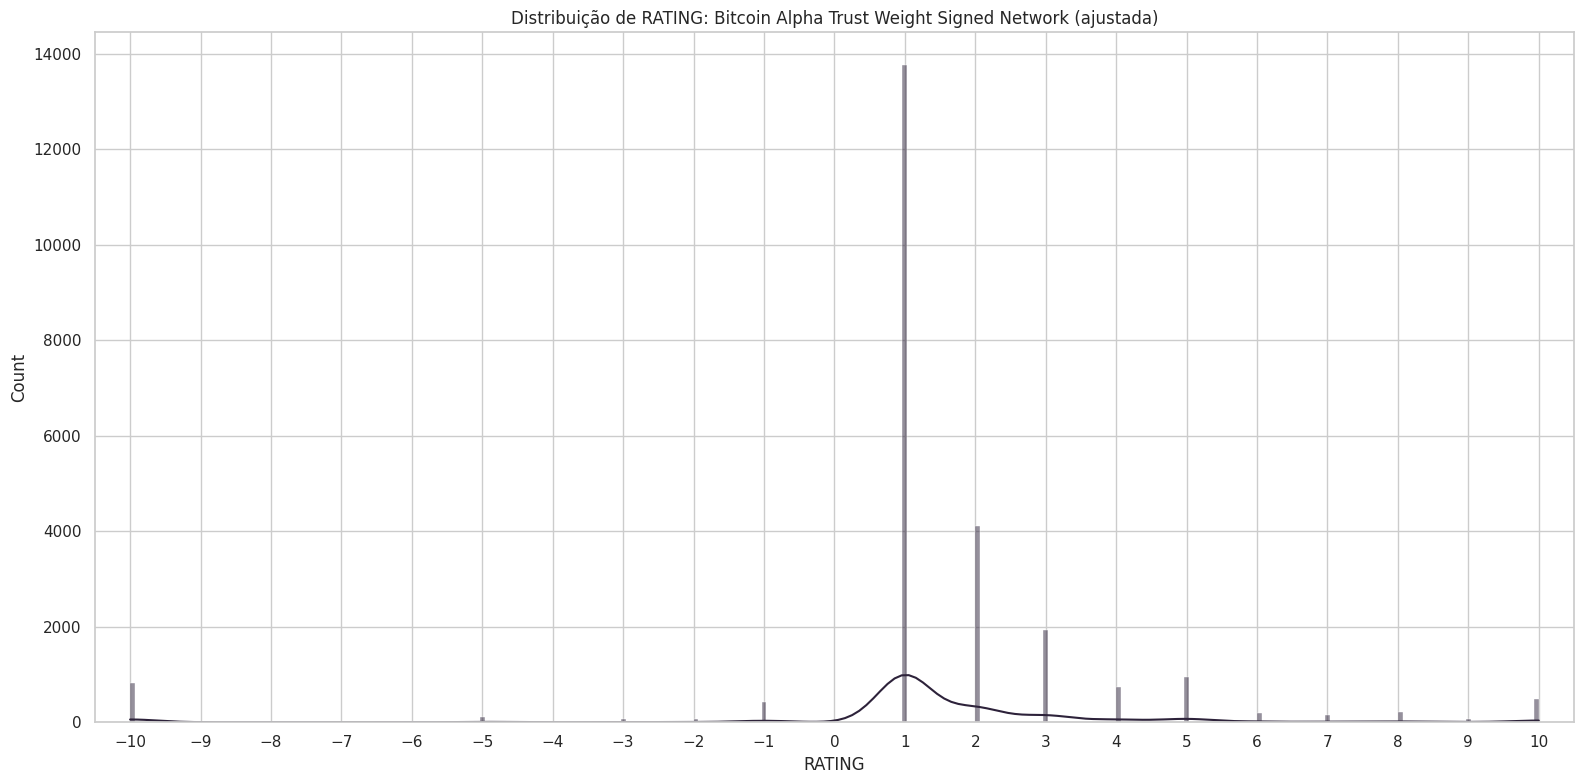

In [33]:
fig, ax = plt.subplots(figsize=(16, 8))

sns.histplot(data=df, x="RATING", kde=True, color=COR_DESTAQUE, ax=ax)

ax.set_xlim(-10.5, 10.5)
ax.set_xticks(np.arange(-10, 11, 1))

ax.set_title("Distribuição de RATING: Bitcoin Alpha Trust Weight Signed Network (ajustada)")
plt.tight_layout()
plt.show()

#### Testes de Aderência

*Será se o tempo segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `TIME`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 24186.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — TIME: estatística=0.9525, p-valor=6.358e-65
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


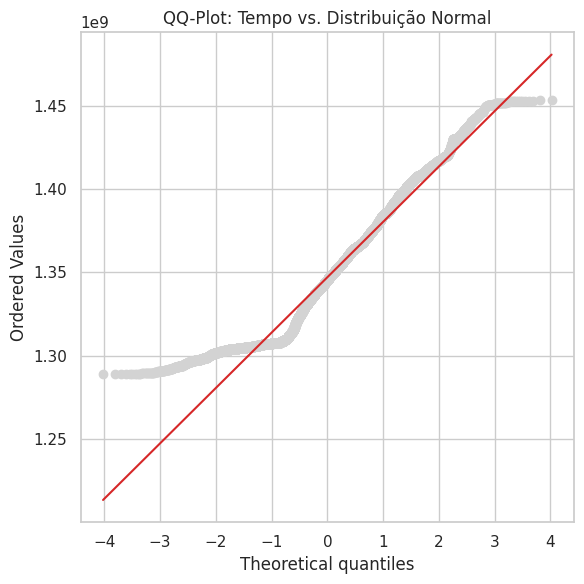

In [34]:
stat_sw, p_valor_sw = stats.shapiro(df["TIME"].dropna())
print(f"Shapiro-Wilk — TIME: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — tempo"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["TIME"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Tempo vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (cinza claro) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

In [35]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
RATING,0.6617,0.0,True
TIME,0.9525,0.0,True


**ECDF — outra forma de ver a distribuição**

Vamos ilustrar com uma única variável (`TIME`, tempo), só pra fixar como essa visualização se lê.

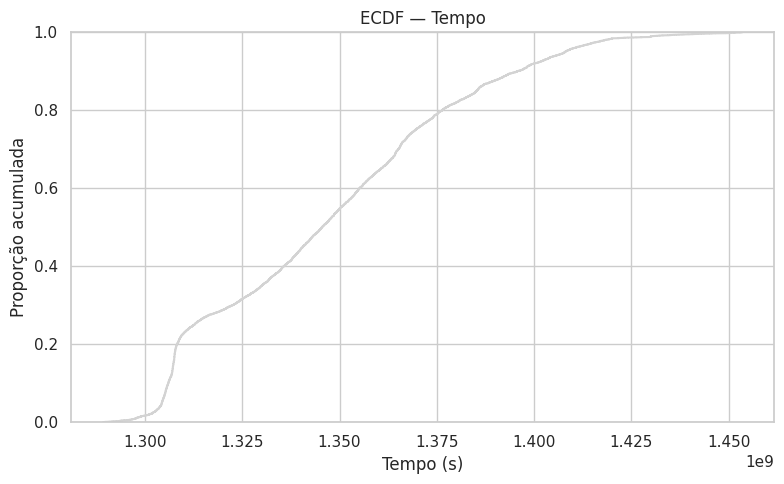

In [36]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="TIME", color=COR_NEUTRA)
plt.title("ECDF — Tempo")
plt.xlabel("Tempo (s)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração das avaliações desse desse dataset demoram esse tempo até aqui".

### Métricas de Tendêncial Central

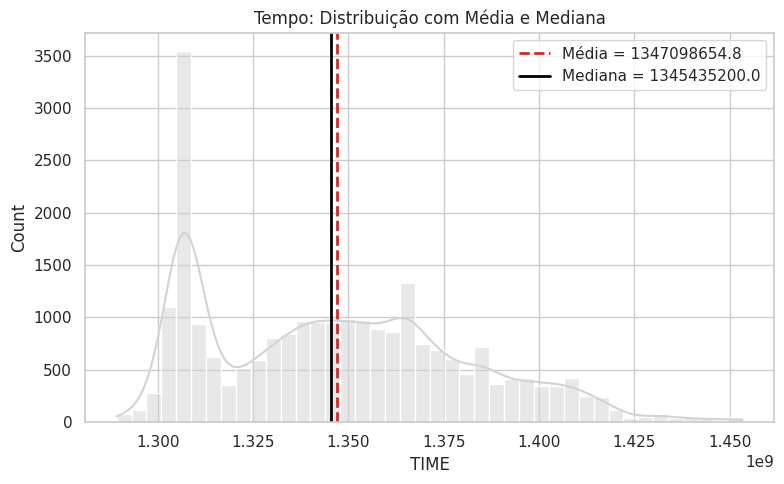

In [37]:
media_time = df["TIME"].mean()
mediana_time = df["TIME"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="TIME", kde=True, color=COR_NEUTRA)
plt.axvline(media_time, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_time:.1f}")
plt.axvline(mediana_time, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_time:.1f}")
plt.title("Tempo: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

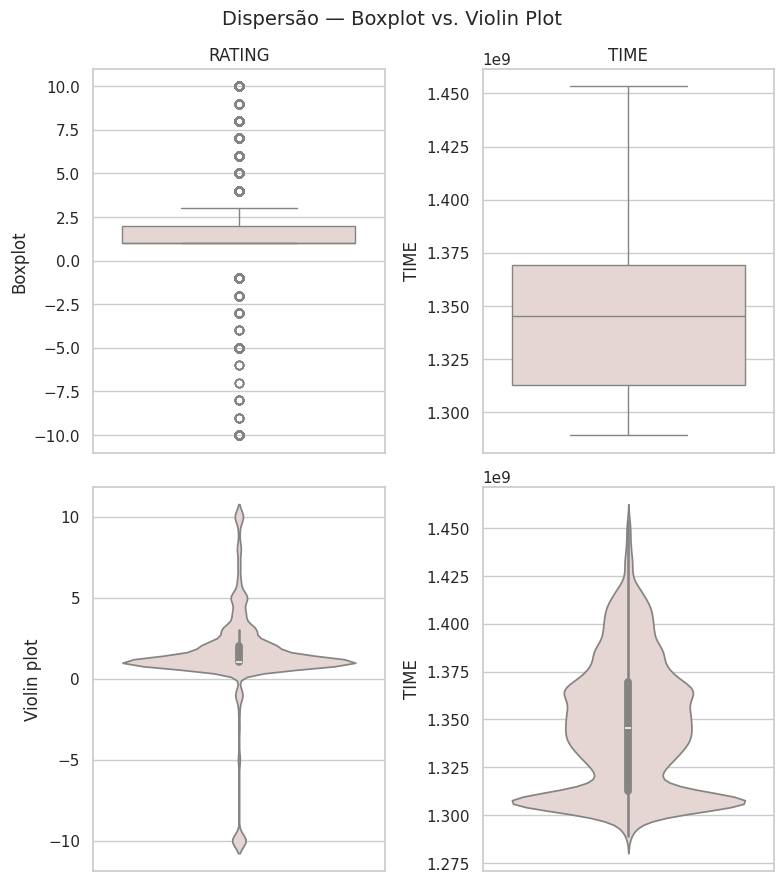

In [38]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot"""

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col,
                color=COR_CONTEXTO, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, y=col,
                    color=COR_CONTEXTO, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Tratamento de Outliers

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [39]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
RATING,-5.000000e-01,3.500000e+00,4380.0
TIME,1.227542e+09,1.454602e+09,0.0


### Visualizando os Outliers

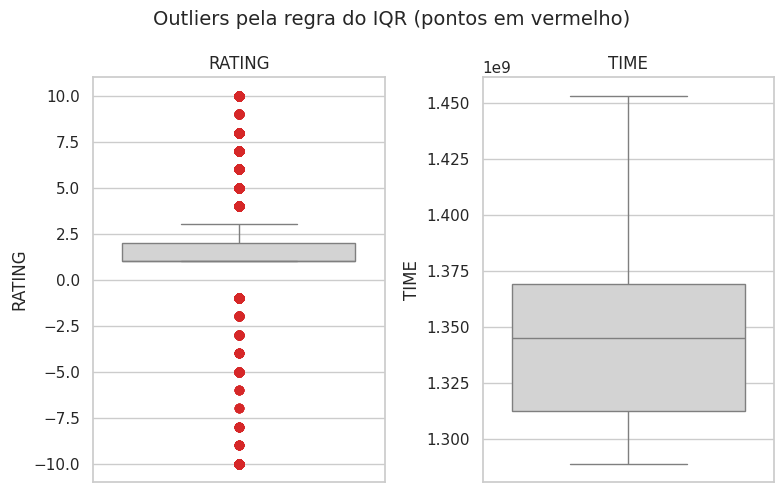

In [40]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

Analisando, percebemos que a coluna `TIME` não possui outliers, porém a coluna `RATING` sim. Porém, são claramente outliers estatísticos que devem ser mantidos. A maioria das notas dadas estão dentre 0 e 3 e a grande minoria foge disso, aparecendo como outlier, porém não são erros de domínio ou falhas.

### Decidindo o Tratamento dos Outliers

**Não vamos remover**. Pelos valores encontrados, a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a avaliação é real).

## 5. Princípio Relacional

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si.

#### Quantitativa x Quantitativa - Correlação

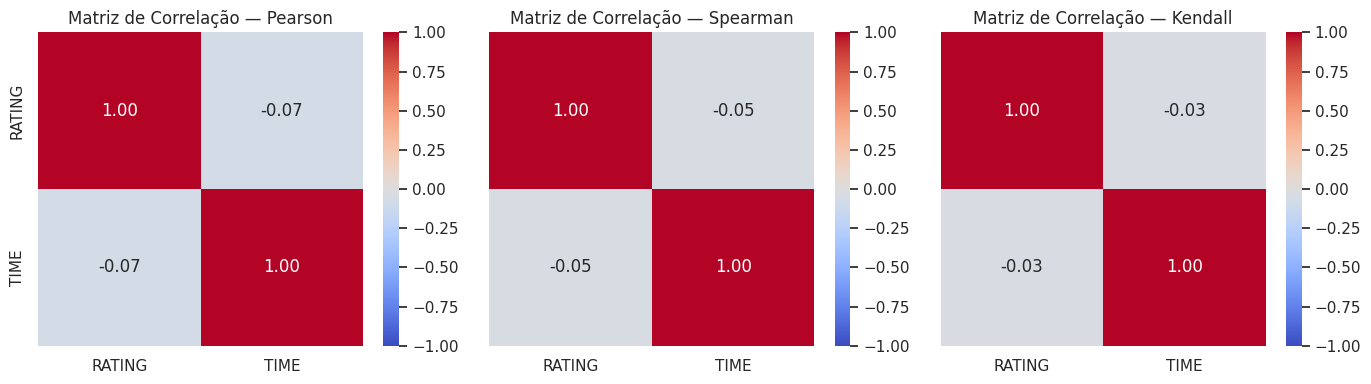

In [41]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

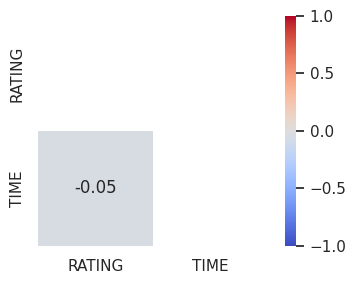

In [42]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

Analisando os resultados obtidos nas etapas anteriores para as variáveis quantitativas (`RATING` e `TIME`), **não há uma divergência significativa** entre os coeficientes de Pearson e Spearman.

###### **O que isso significa?**

Ambos os coeficientes concordam que a relação entre o tempo em que a avaliação foi feita (`TIME`) e a nota atribuída (`RATING`) é **praticamente inexistente (nula)**.

Como o coeficiente de Spearman avalia relações monotônicas gerais (mesmo não lineares) e o de Pearson foca na relação puramente linear, a proximidade dos valores indica que mudar a perspectiva de análise linear para uma análise baseada em postos (ranks) não revelou nenhum padrão oculto de associação entre as duas variáveis.

#### Dispersão (scatter) entre as variáveis quantitativas

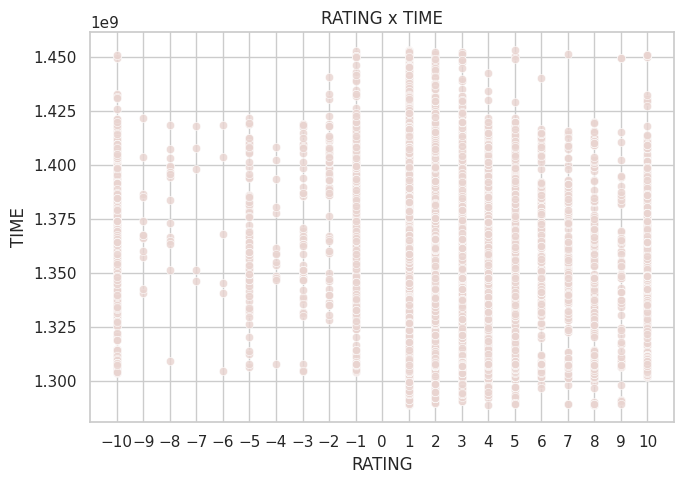

In [43]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="RATING", y="TIME",
                color=COR_CONTEXTO, alpha=0.8)
plt.title("RATING x TIME")
plt.xlabel("RATING")
plt.ylabel("TIME")
plt.xticks(np.arange(-10, 11, 1))
plt.tight_layout()
plt.show()

Olhando para o gráfico de dispersão (`scatterplot`) entre `RATING` e `TIME`, **não existe nenhuma tendência visível clara** (como uma linha ascendente ou descendente) que aponte para um comportamento estruturado ao longo do tempo.

Podemos tirar as seguintes conclusões dessa distribuição visual:

1. **Distribuição Uniforme no Tempo:** Para praticamente qualquer valor de nota atribuída (RATING), os pontos cobrem quase todo o intervalo do eixo Y (desde o início do histórico até o final). Isso significa que notas extremamente positivas ou negativas são dadas de maneira contínua ao longo de todo o período, sem uma época específica concentrando apenas avaliações ruins ou excelentes.
2. **Concentração Vertical (Densidade):** Há visivelmente faixas muito mais densas nas colunas de notas positivas baixas, mostrando que o fluxo de avaliações é constante e majoritariamente positivo independente do momento histórico do dataset.
3. **Ausência de Correlação:** A disposição dos pontos em colunas verticais paralelas e bem distribuídas reforça o que os coeficientes de Pearson e Spearman já haviam indicado estatisticamente: as duas variáveis são praticamente independentes uma da outra.

##### Matriz de Correlação

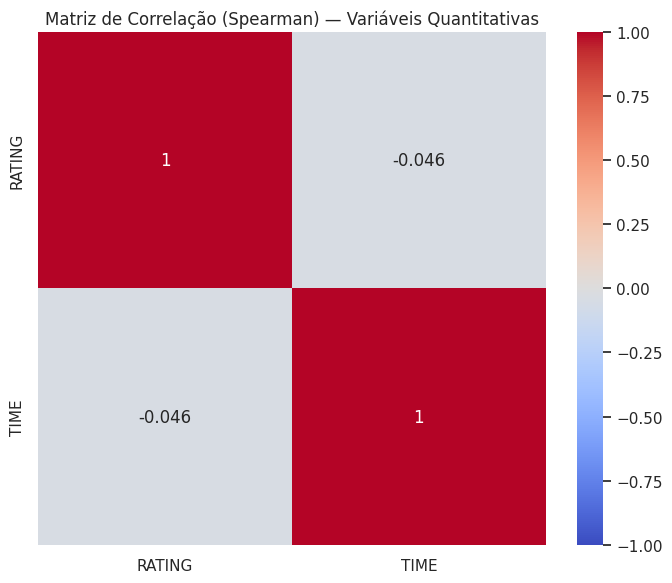

In [44]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Relações muito fracas.

## 6. Síntese e Principais Conclusões da EDA

Com base na Análise Exploratória de Dados realizada no dataset *Bitcoin Alpha*, podemos sintetizar os achados mais importantes nos seguintes pontos:

1. **Estrutura dos Dados e Consistência:** O conjunto de dados conta com **24.186 registros** e 4 colunas (`SOURCE`, `TARGET`, `RATING` e `TIME`). Não existem dados nulos nem registros duplicados, indicando uma excelente integridade inicial da base.
2. **Altíssima Assimetria nas Avaliações (`RATING`):** A variável de reputação possui forte assimetria negativa ($-1.35$) e curtose bastante elevada ($7.64$). Isso ocorre porque as avaliações são massivamente positivas (com grande pico em $+1$), apresentando caudas pesadas com valores extremos legítimos (como $-10$ e $+10$) que funcionam como outliers estatísticos, mas que refletem interações reais da rede de confiança.
3. **Não-Normalidade Estrita:** Nenhuma das variáveis numéricas segue uma distribuição normal. O teste de *Shapiro-Wilk* rejeitou a hipótese de normalidade com significância estatística extrema ($p \approx 0$), padrão confirmado visualmente pelos gráficos de histograma e pelo comportamento desviante das caudas no gráfico quantil-quantil (*QQ-Plot*).
4. **Independência Temporal das Notas:** A análise relacional bivariada revelou que a nota atribuída não sofre influência do tempo. O gráfico de dispersão mostra uma distribuição altamente homogênea dos ratings de $-10$ a $10$ ao longo de todo o período histórico.
5. **Correlação Praticamente Nula:** Todos os coeficientes calculados (Pearson: $-0.07$, Spearman: $-0.05$ e Kendall: $-0.03$) confirmam uma associação extremamente fraca ou inexistente entre o momento da transação e a nota de confiança dada, indicando que o comportamento de reputação dos agentes da rede não se alterou de forma linear ou monotônica conforme o tempo passou.